In [ ]:
NAME = ""
ID = ""

---

# Matplotlib: Visualization with Python

Most information is from [matplotlib.org](https://matplotlib.org/).

Matplotlib is a comprehensive library for creating static, animated, and interactive visualizations in Python.

Matplotlib makes easy things easy and hard things possible.
![matplotlib](img/ch16.matplotlib1.png)

## 1 Introduction

### A simple example
Matplotlib graphs your data on Figures (i.e., windows, Jupyter widgets, etc.), each of which can contain one or more Axes (i.e., an area where points can be specified in terms of x-y coordinates, or theta-r in a polar plot, or x-y-z in a 3D plot, etc.). The simplest way of creating a figure with an axes is using pyplot.subplots. We can then use Axes.plot to draw some data on the axes:

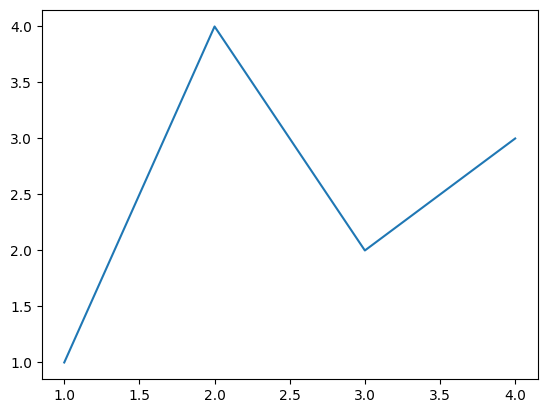

In [1]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots()  # Create a figure containing a single axes.
ax.plot([1, 2, 3, 4], [1, 4, 2, 3])  # Plot some data on the axes.

### Parts of a Figure
Now, let's have a deeper look at the components of a Matplotlib figure.

<div align="center">
    <img src="img/ch16.figurePart.png" width="60%">
</div>


#### Figure
The figure keeps track of all the child Axes, titles, figure legends, etc. A figure can contain any number of Axes, but will typically have at least one.

#### Axes
This is what you think of as 'a plot', it is the region of the image with the data space. A given figure can contain many Axes, but a given Axes object can only be in one Figure. The Axes contains two (or three in the case of 3D) Axis objects which take care of the data limits (the data limits can also be controlled via the [axes.Axes.set_xlim()](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set_xlim.html) and [axes.Axes.set_ylim()](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set_ylim.html) methods). Each Axes has a title (set via [set_title()](https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.axes.Axes.set_title.html)), an x-label (set via [set_xlabel()](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set_xlabel.html)), and a y-label set via [set_ylabel()](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set_ylabel.html)).

It's convenient to create the axes together with the figure, but you can also add axes later on, allowing for more complex axes layouts.

#### Axis
They take care of setting the graph limits and generating the ticks (the marks on the axis) and ticklabels (strings labeling the ticks). The location of the ticks is determined by a [Locator](https://matplotlib.org/stable/api/ticker_api.html#matplotlib.ticker.MultipleLocator) object and the ticklabel strings are formatted by a [Formatter](https://matplotlib.org/stable/gallery/ticks_and_spines/tick-formatters.html). The combination of the correct Locator and Formatter gives very fine control over the tick locations and labels.

#### Artist
Basically, everything you can see on the figure is an artist (even the Figure, Axes, and Axis objects). This includes Text objects, Line2D objects, collections objects, Patch objects ... When the figure is rendered, all of the artists are drawn to the canvas. Most Artists are tied to an Axes; such an Artist cannot be shared by multiple Axes, or moved from one to another.

### The object-oriented interface and the pyplot interface

As noted above, there are essentially two ways to use Matplotlib:

1. Explicitly create figures and axes, and call methods on them (the "object-oriented (OO) style").
2. Rely on pyplot to automatically create and manage the figures and axes, and use pyplot functions for plotting.

In general, pyplot is mainly intended for interactive plots and simple cases of programmatic plot generation. The object-oriented API is recommended for more complex plots.

In this course, we will focus on pyplot.

Object-Oriented (OO) style:

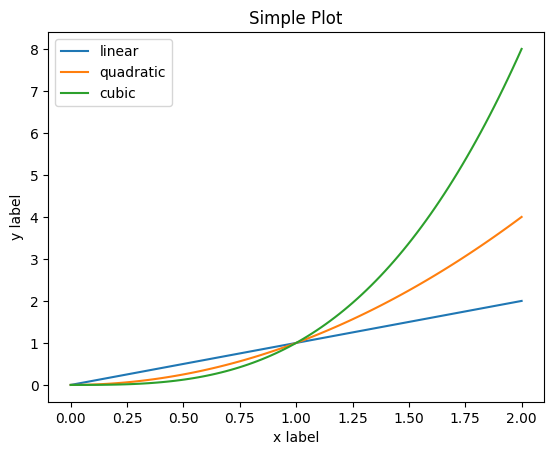

In [2]:
# Note that even in the OO-style, we use `.pyplot.figure` to create the figure.
x = np.linspace(0, 2, 100)

# Create a figure and an axes.
fig, ax = plt.subplots()  

# Plot some data on the axes.
ax.plot(x, x, label='linear')  
ax.plot(x, x**2, label='quadratic')  # Plot more data on the axes...
ax.plot(x, x**3, label='cubic')  # ... and some more.

# Add an x-label and y-label to the axes.
ax.set_xlabel('x label') 
ax.set_ylabel('y label') 

# Add a title to the axes.
ax.set_title("Simple Plot")  

# Add a legend using label from each plot.
ax.legend()  

Or pyplot style:

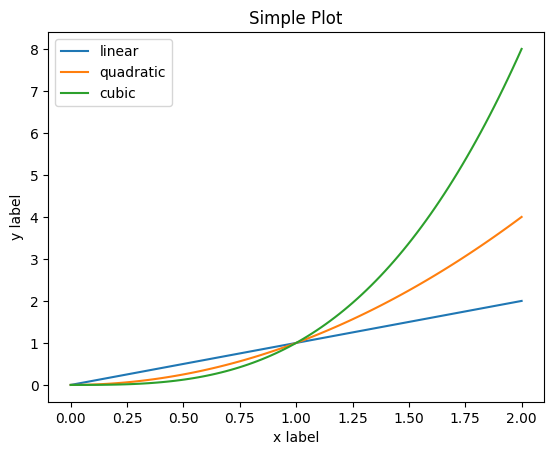

In [3]:
x = np.linspace(0, 2, 100)

plt.figure() # This statement could be omitted.

# Plot some data on the (implicit) axes.
plt.plot(x, x, label='linear')  
plt.plot(x, x**2, label='quadratic') 
plt.plot(x, x**3, label='cubic')

# customize the figure
plt.xlabel('x label')
plt.ylabel('y label')
plt.title("Simple Plot")
plt.legend()

Typically one finds oneself making the same plots over and over again, but with different data sets, which leads to needing to write specialized functions to do the plotting. The recommended function signature is something like:

In [5]:
def my_plotter(ax, data1, data2, param_dict):
    """
    A helper function to make a graph

    Parameters
    ----------
    ax : Axes
        The axes to draw to

    data1 : array
       The x data

    data2 : array
       The y data

    param_dict : dict
       Dictionary of kwargs to pass to ax.plot

    Returns
    -------
    out : list
        list of artists added
    """
    out = ax.plot(data1, data2, **param_dict)
    return out

which you would then use as:

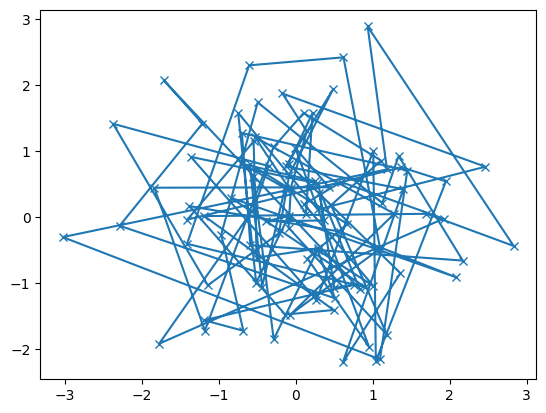

In [6]:
data1, data2, data3, data4 = np.random.randn(4, 100)
fig, ax = plt.subplots(1, 1)
my_plotter(ax, data1, data2, {'marker': 'x'})

or if you wanted to have 2 sub-plots:

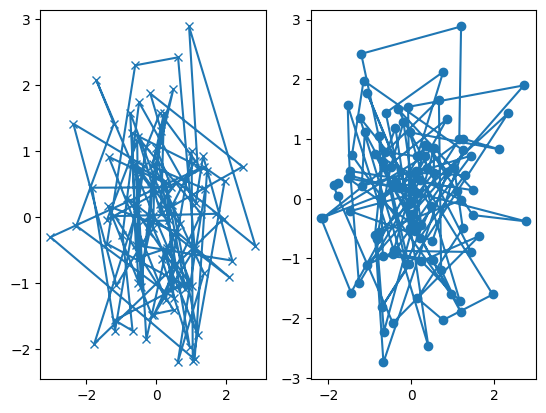

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2)
my_plotter(ax1, data1, data2, {'marker': 'x'})
my_plotter(ax2, data3, data4, {'marker': 'o'})

## 2. Pyplot tutorial

### Intro to pyplot

matplotlib.pyplot is a state-based interface to matplotlib.

Each pyplot function makes some change to a figure: e.g., creates a figure, creates a plotting area in a figure, plots some lines in a plotting area, decorates the plot with labels, etc.

The list of pyplot function is available [here](https://matplotlib.org/stable/plot_types/index.html).

In `matplotlib.pyplot` various states are preserved across function calls, so that it keeps track of things like the current figure and plotting area, and the plotting functions are directed to the current axes.

The pyplot API is generally less-flexible than the object-oriented API. Most of the function calls you see here can also be called as methods from an Axes object.

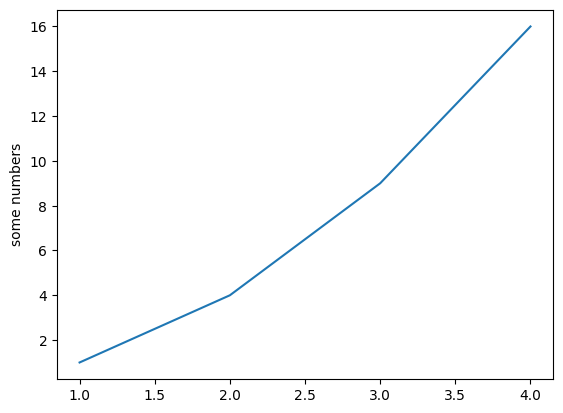

In [10]:
import matplotlib.pyplot as plt
plt.plot([1, 2, 3, 4], [1, 4, 9, 16])
plt.ylabel('some numbers')
plt.show()

#### Formatting the style of your plot
For every x, y pair of arguments, there is an optional third argument which is the format string that indicates the color and line type of the plot. You concatenate a color string with a line style string. The default format string is 'b-', which is a solid blue line. 

A format string consists of a part for color, marker and line:

fmt = '[marker][line][color]'

<div align="center">
	<img src="img/ch16.styplecase.png" width="70%">
</div>

Each of them is optional. If not provided, the value from the style cycle is used. Exception: If line is given, but no marker, the data will be a line without markers.
<div align="center">
	<img src="img/ch16.style.jpg" width="70%">
</div>

For example, to plot the above with red circles, you would issue

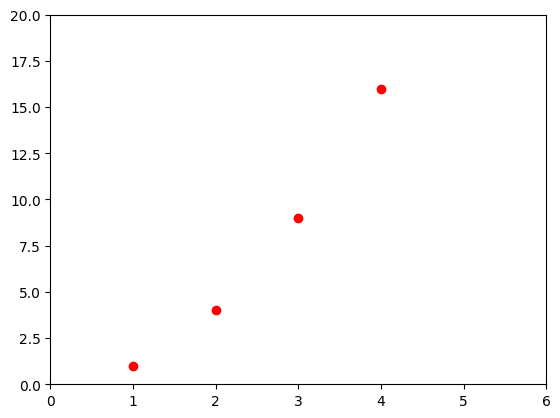

In [11]:
plt.plot([1, 2, 3, 4], [1, 4, 9, 16], 'ro')
plt.axis([0, 6, 0, 20]) # limit for x,y-axis([xmin, xmax, ymin, ymax])
plt.show()

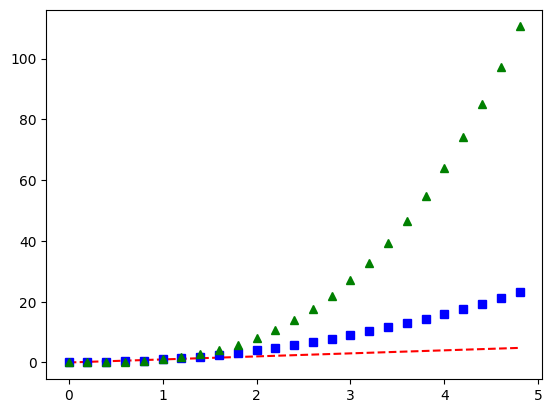

In [12]:
# evenly sampled time at 200ms intervals
t = np.arange(0., 5., 0.2)

# red dashes, blue squares and green triangles
# two method to plot:

# method 1
# plt.plot(t, t, 'r--', t, t**2, 'bs', t, t**3, 'g^')
# plt.show()

# method 2
plt.plot(t, t, 'r--')
plt.plot(t, t**2, 'bs')
plt.plot(t, t**3, 'g^')
plt.show()



### Plotting with keyword strings

There are some instances where you have data in a format that lets you access particular variables with strings. For example, with [numpy.recarray](https://numpy.org/doc/stable/reference/generated/numpy.recarray.html) or pandas.DataFrame.

Matplotlib allows you provide such an object with the data keyword argument. If provided, then you may generate plots with the strings corresponding to these variables.

{'a': array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), 'c': array([3, 0, 9, 2, 9, 2, 0, 1, 3, 1]), 'd': array([203.04104262, 583.43488042, 435.51960678, 373.14312577,
       707.04684619, 434.33971921, 373.96532479, 723.15577491,
        31.17417467, 478.11519607]), 'b': array([  1.47958122,   8.46945419,   9.21503897,  23.50573703,
       -26.93001797,  14.83442216,   1.66290974,   1.0991969 ,
        12.23524881,   9.615337  ])}


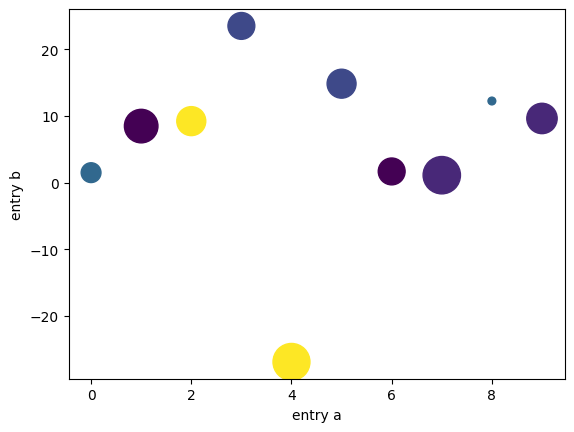

In [13]:
# data
data = {'a': np.arange(10),
        'c': np.random.randint(0, 10, 10),
        'd': np.random.randn(10)}
data['b'] = data['a'] + 10 * np.random.randn(10)
data['d'] = np.abs(data['d']) * 500
print(data)

# plot
# c=color s=size
plt.scatter('a', 'b', c='c', s='d', data=data) # data=data represents the data keyword argument
plt.xlabel('entry a')
plt.ylabel('entry b')
plt.show()

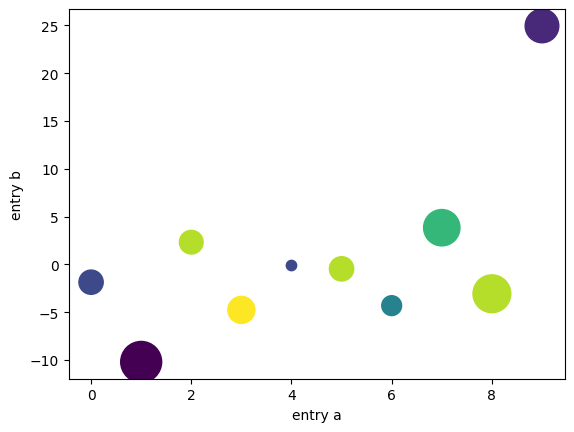

In [14]:
# data
a = np.arange(10)
b = a + 10 * np.random.randn(10)
c = np.random.randint(0, 10, 10)
d = np.abs(np.random.randn(10))*500

# plot
plt.scatter(a, b, c=c, s=d) # cmap default: 'viridis'
plt.xlabel('entry a')
plt.ylabel('entry b')
plt.show()

### Plotting with categorical variables
It is also possible to create a plot using categorical variables. Matplotlib allows you to pass categorical variables directly to many plotting functions. For example:

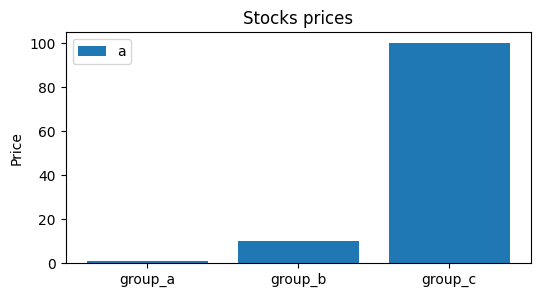

In [15]:
names = ['group_a', 'group_b', 'group_c']
values = [1, 10, 100]

plt.figure(figsize=(6, 3))
plt.bar(names, values, label = 'a')
plt.title('Stocks prices')
plt.ylabel('Price')
plt.legend()
plt.show()

## 3. Working with multiple figures and axes

### Pyplot styple

Pyplot has the concept of the current figure and the current axes. All plotting functions apply to the current axes. 

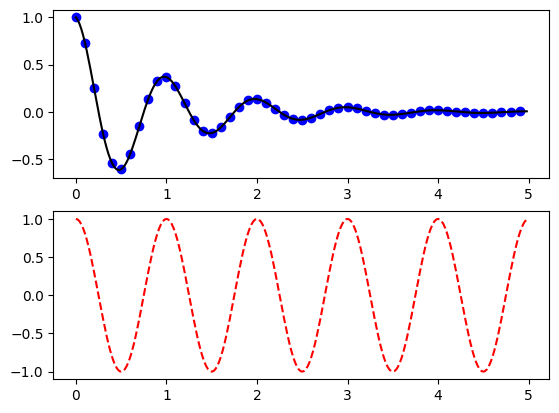

In [18]:
def f(t):
    return np.exp(-t) * np.cos(2*np.pi*t)

t1 = np.arange(0.0, 5.0, 0.1)
t2 = np.arange(0.0, 5.0, 0.02)

plt.figure()
plt.subplot(2,1,1) 
plt.plot(t1, f(t1), 'bo', t2, f(t2), 'k')

plt.subplot(212)
plt.plot(t2, np.cos(2*np.pi*t2), 'r--')
plt.show()

The figure call here is optional because a figure will be created if none exists, just as an axes will be created (equivalent to an explicit subplot() call) if none exists. 

The [subplot](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplot.html) call specifies *numrows*, *numcols*, *plot_number* where plot_number ranges from 1 to numrows$*$numcols. The commas in the subplot call are optional if numrows$*$numcols<10. So subplot(211) is identical to subplot(2, 1, 1).

You can create an arbitrary number of subplots and axes. If you want to place an axes manually, i.e., not on a rectangular grid, use axes, which allows you to specify the location as axes([left, bottom, width, height]) where all values are in fractional (0 to 1) coordinates. See [Axes Demo](https://matplotlib.org/stable/gallery/subplots_axes_and_figures/axes_demo.html) for an example of placing axes manually and Basic Subplot Demo for an example with lots of subplots.

You can create multiple figures by using multiple figure calls with an increasing figure number. Of course, each figure can contain as many axes and subplots as your heart desires:

Text(0.5, 0.98, 'Figure 1')

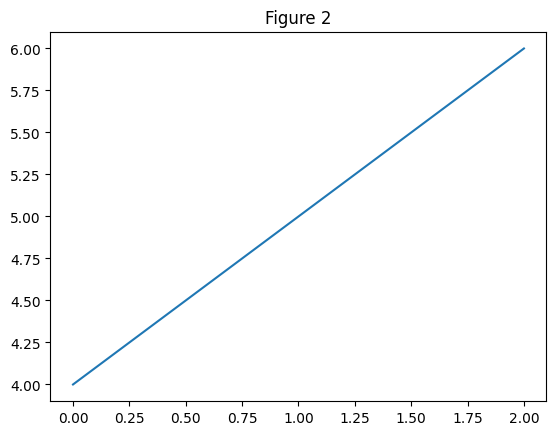

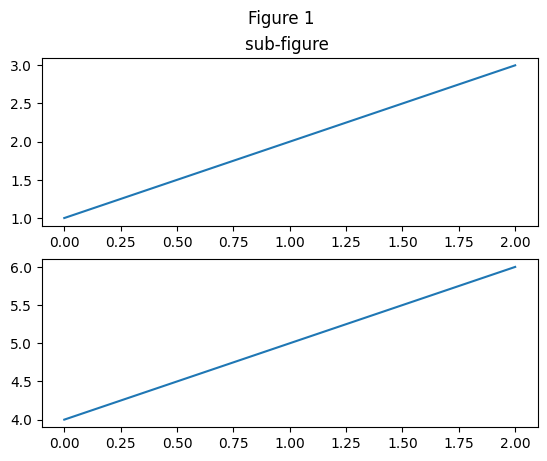

In [19]:
import matplotlib.pyplot as plt

# the 1st figure
plt.figure(1)               
plt.subplot(211)             # the first subplot in the first figure
plt.plot([1, 2, 3])
plt.subplot(212)             # the second subplot in the first figure
plt.plot([4, 5, 6])

# a 2nd figure
plt.figure(2)                
plt.plot([4, 5, 6])          # creates a subplot() by default
plt.title('Figure 2')

# figure 1 again
plt.figure(1)                # figure 1 current; subplot(212) still current
plt.subplot(211)             # make subplot(211) in figure1 current
plt.title('sub-figure ') 
plt.suptitle('Figure 1')     # subplot 211 title

### Object-oriented style


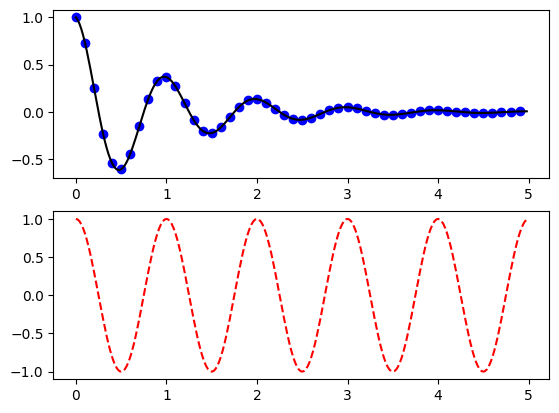

In [20]:
# fig = plt.figure()  # an empty figure with no Axes
fig, axs = plt.subplots(2, 1)  # a figure with a 2x2 grid of Axes
axs[0].plot(t1, f(t1), 'bo', t2, f(t2), 'k')
axs[1].plot(t2, np.cos(2*np.pi*t2), 'r--')

There are essentially two ways to use create multiple figures and axes with object-oriented style and pyplot style. 

Text(0.5, 0.98, 'Categorical Plotting')

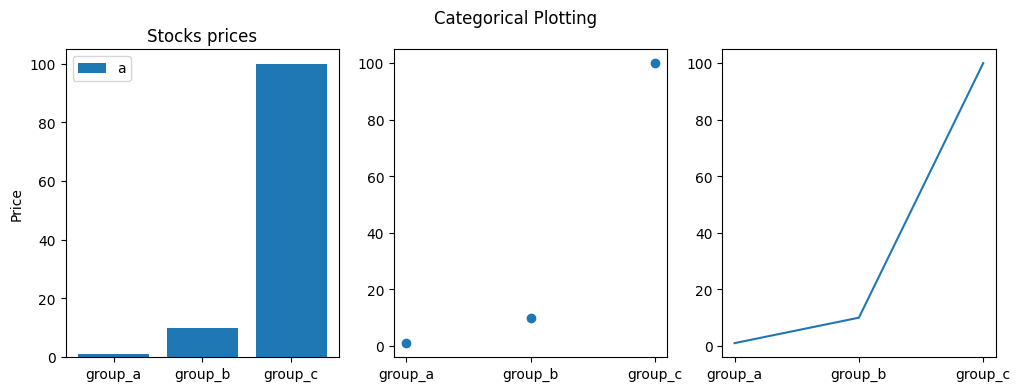

In [21]:
names = ['group_a', 'group_b', 'group_c']
values = [1, 10, 100]

# ----------  object-oriented style
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4))
ax1.bar(names, values, label = 'a')
ax1.set_title('Stocks prices')
ax1.set_ylabel('Price')
ax1.legend()

ax2.scatter(names, values)

ax3.plot(names, values)

fig.suptitle('Categorical Plotting')

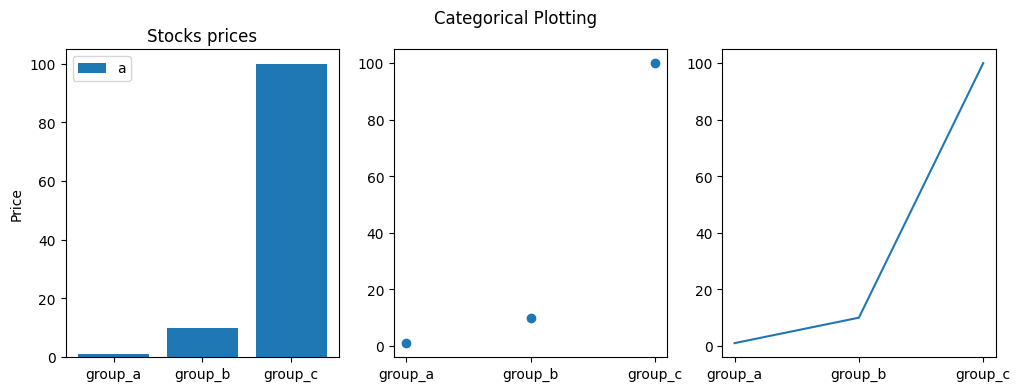

In [22]:
# ----------- pyplot style
plt.figure(figsize=(12, 4))

plt.subplot(1,3,1)
plt.bar(names, values, label = 'a')
plt.title('Stocks prices')
plt.ylabel('Price')
plt.legend()

plt.subplot(132)
plt.scatter(names, values)

plt.subplot(133)
plt.plot(names, values)

plt.suptitle('Categorical Plotting')
plt.show()

If you are making lots of figures, you need to be aware of one more thing: the memory required for a figure is not completely released until the figure is explicitly closed with close. 

You can clear the current figure with clf and the current axes with cla. However, deleting all references to the figure is not enough, because pyplot maintains internal references until close is called.

- cla()   # Clear axis
- clf()   # Clear figure
- close() # Close a figure window

## 4. Working with text
Text can be used in an arbitrary location, and *xlabel*, *ylabel* and *title* are used to add text in the indicated locations (see [Text in Matplotlib Plots](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.text.html) for a more detailed example).

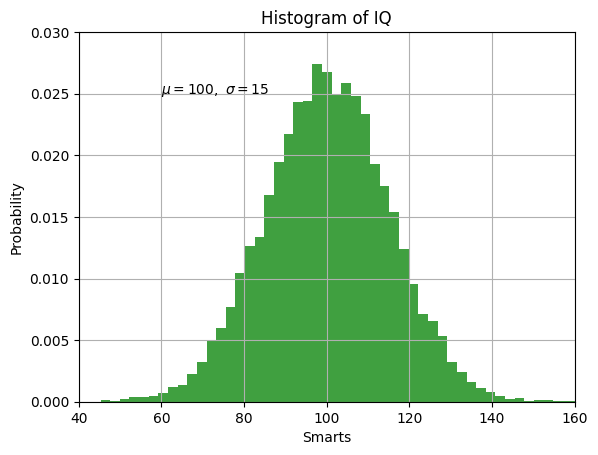

In [24]:
mu, sigma = 100, 15
x = mu + sigma * np.random.randn(10000)

# the histogram of the data
n, bins, patches = plt.hist(x, 50, density=1, facecolor='g', alpha=0.75)

plt.xlabel('Smarts')
plt.ylabel('Probability')
plt.title('Histogram of IQ')
plt.text(60, .025, r'$\mu=100,\ \sigma=15$')
plt.axis([40, 160, 0, 0.03])
plt.grid(True)

plt.show()

The *r* preceding the title string is important -- it signifies that the string is a raw string and not to treat backslashes as python escapes.

### Annotating text
Another common use for text is to annotate some feature of the plot, and the annotate method provides helper functionality to make annotations easy. In an annotation, there are two points to consider: the location being annotated represented by the argument xy and the location of the text xytext. Both of these arguments are (x, y) tuples.

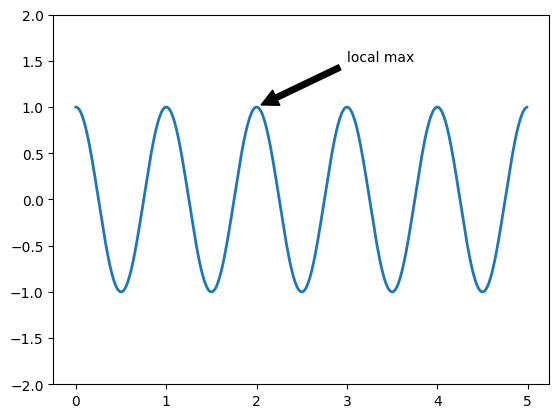

In [31]:
ax = plt.subplot()

t = np.arange(0.0, 5.0, 0.01)
s = np.cos(2*np.pi*t)
line, = plt.plot(t, s, lw=2)

plt.annotate('local max', xy=(2, 1), xytext=(3, 1.5),
             arrowprops=dict(facecolor='black', shrink=0.05),
             ) 

plt.ylim(-2, 2)
plt.show()

In this basic example, both the xy (arrow tip) and xytext locations (text location) are in data coordinates. You can check more advanced annotation uses for [details](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.annotate.html).

## 5. Logarithmic and other nonlinear axes
matplotlib.pyplot supports not only linear axis scales, but also logarithmic and logit scales. This is commonly used if data spans many orders of magnitude. Changing the scale of an axis is easy by using [plt.xscale( )](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xscale.html) and [plt.yscale( )](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.yscale.html#matplotlib.pyplot.yscale).
An example of four plots with the same data and different scales for the y axis is shown below.

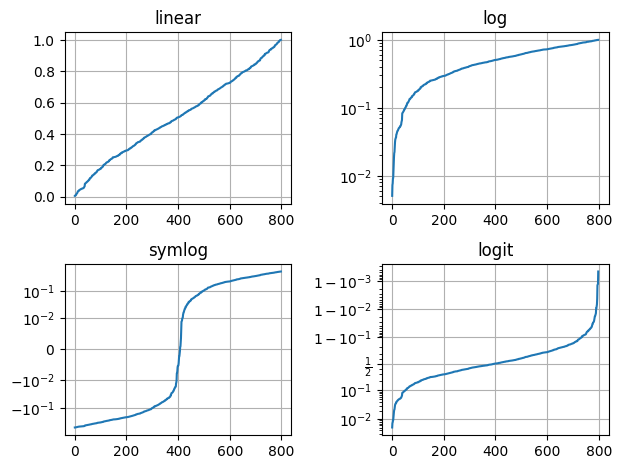

In [32]:
# Fixing random state for reproducibility
np.random.seed(19680801)

# make up some data in the open interval (0, 1)
y = np.random.normal(loc=0.5, scale=0.4, size=1000) # loc: mean, scale: std, size:number of data
y = y[(y > 0) & (y < 1)]
y.sort()
x = np.arange(len(y))

# plot with various axes scales
plt.figure()

# linear
plt.subplot(221)
plt.plot(x, y)
plt.yscale('linear')
plt.title('linear')
plt.grid(True)

# log 对数尺度
plt.subplot(222)
plt.plot(x, y)
plt.yscale('log')
plt.title('log')
plt.grid(True)

# symmetric log
plt.subplot(223)
plt.plot(x, y - y.mean())
plt.yscale('symlog', linthresh=0.01)
plt.title('symlog')
plt.grid(True)

# logit
plt.subplot(224)
plt.plot(x, y)
plt.yscale('logit')
plt.title('logit')
plt.grid(True)
# Adjust the subplot layout, because the logit one may take more space
# than usual, due to y-tick labels like "1 - 10^{-3}"
plt.subplots_adjust(top=0.92, bottom=0.08, left=0.10, right=0.95, hspace=0.35,
                    wspace=0.4)

plt.show()

You may save your figure with a given name and location with [savefig()](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.savefig.html).

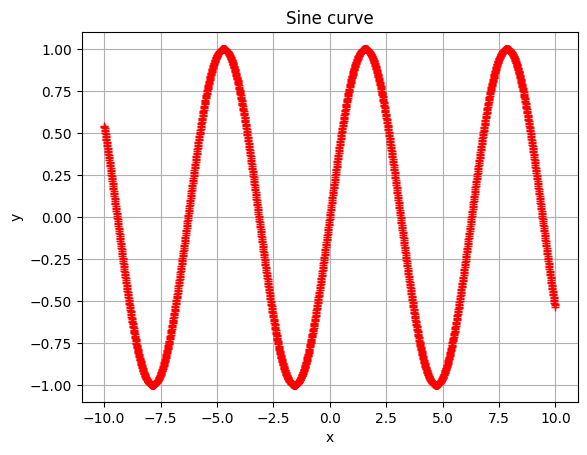

In [33]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

# Data for plotting
t = np.arange(-10, 10, 0.01)
s = np.sin(t)

# Object-Oriented style
fig, ax = plt.subplots()
ax.plot(t, s, 'r+') 

ax.set(xlabel='x', ylabel='y',
       title='Sine curve')
ax.grid()

fig.savefig("test.png")
plt.show()

## 6. Image tutorial
### Importing image 
The image module supports basic image loading, rescaling and display operations.

In [34]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread('img/ch16.stinkbug.png')
print (img.shape)
print(img)

(375, 500, 3)
[[[0.40784314 0.40784314 0.40784314]
  [0.40784314 0.40784314 0.40784314]
  [0.40784314 0.40784314 0.40784314]
  ...
  [0.42745098 0.42745098 0.42745098]
  [0.42745098 0.42745098 0.42745098]
  [0.42745098 0.42745098 0.42745098]]

 [[0.4117647  0.4117647  0.4117647 ]
  [0.4117647  0.4117647  0.4117647 ]
  [0.4117647  0.4117647  0.4117647 ]
  ...
  [0.42745098 0.42745098 0.42745098]
  [0.42745098 0.42745098 0.42745098]
  [0.42745098 0.42745098 0.42745098]]

 [[0.41960785 0.41960785 0.41960785]
  [0.41568628 0.41568628 0.41568628]
  [0.41568628 0.41568628 0.41568628]
  ...
  [0.43137255 0.43137255 0.43137255]
  [0.43137255 0.43137255 0.43137255]
  [0.43137255 0.43137255 0.43137255]]

 ...

 [[0.4392157  0.4392157  0.4392157 ]
  [0.43529412 0.43529412 0.43529412]
  [0.43137255 0.43137255 0.43137255]
  ...
  [0.45490196 0.45490196 0.45490196]
  [0.4509804  0.4509804  0.4509804 ]
  [0.4509804  0.4509804  0.4509804 ]]

 [[0.44313726 0.44313726 0.44313726]
  [0.44313726 0.4431372

### Plotting numpy arrays as images
So, you have your data in a numpy array (either by importing it, or by generating it). Let's render it. In Matplotlib, this is performed using the imshow() function. 

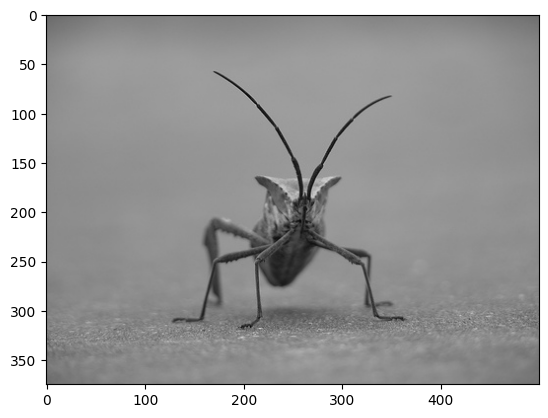

In [35]:
imgplot = plt.imshow(img)

### Applying pseudocolor schemes to image plots
Pseudocolor can be a useful tool for enhancing contrast and visualizing your data more easily. This is especially useful when making presentations of your data using projectors - their contrast is typically quite poor.

Pseudocolor is only relevant to single-channel, grayscale, luminosity images. We currently have an RGB image. Since R, G, and B are all similar (see for yourself above or in your data), we can just pick one channel of our data:

[[0.40784314 0.40784314 0.40784314 ... 0.42745098 0.42745098 0.42745098]
 [0.4117647  0.4117647  0.4117647  ... 0.42745098 0.42745098 0.42745098]
 [0.41960785 0.41568628 0.41568628 ... 0.43137255 0.43137255 0.43137255]
 ...
 [0.4392157  0.43529412 0.43137255 ... 0.45490196 0.4509804  0.4509804 ]
 [0.44313726 0.44313726 0.4392157  ... 0.4509804  0.44705883 0.44705883]
 [0.44313726 0.4509804  0.4509804  ... 0.44705883 0.44705883 0.44313726]]


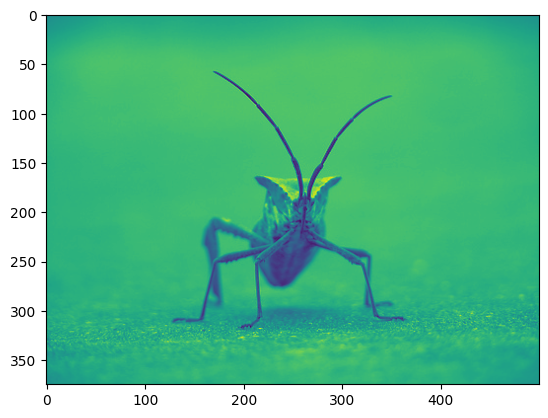

In [36]:
lum_img = img[:, :, 0]
print(lum_img)

# This is array slicing.  You can read more in the `Numpy section`.

plt.imshow(lum_img)

Now, with a luminosity (2D, no color) image, the default colormap (aka lookup table, LUT), is applied. The default is called viridis. There are plenty of others to choose from. The list of [colormaps in is available at here]( https://matplotlib.org/stable/tutorials/colors/colormaps.html).

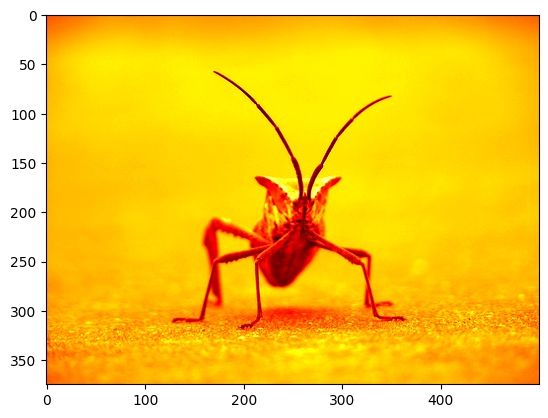

In [37]:
plt.imshow(lum_img, cmap="hot")

Note that you can also change colormaps on existing plot objects using the set_cmap() method. 

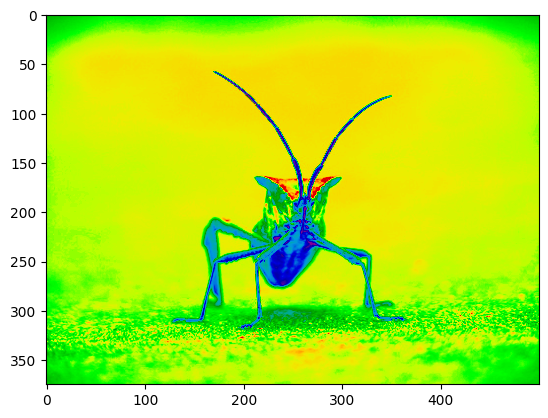

In [38]:
imgplot = plt.imshow(lum_img)
imgplot.set_cmap('nipy_spectral')

### Color scale reference
It's helpful to have an idea of what value a color represents. We can do that by adding a color bar to your figure:

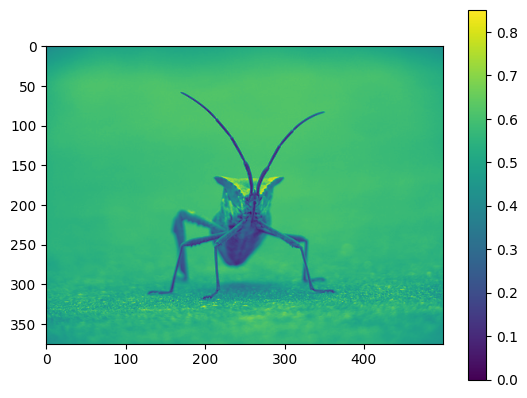

In [40]:
imgplot = plt.imshow(lum_img)
plt.colorbar()

### Examining a specific data range
Sometimes you want to enhance the contrast in your image, or expand the contrast in a particular region while sacrificing the detail in colors that don't vary much, or don't matter. A good tool to find interesting regions is the histogram. To create a histogram of our image data, we use the [hist()](https://matplotlib.org/stable/tutorials/introductory/images.html) function.

(array([2.000e+00, 2.000e+00, 3.000e+00, 3.000e+00, 2.000e+00, 2.000e+00,
        3.000e+00, 1.000e+00, 7.000e+00, 9.000e+00, 7.000e+00, 2.000e+00,
        7.000e+00, 1.000e+01, 1.100e+01, 1.500e+01, 1.400e+01, 2.700e+01,
        2.100e+01, 2.400e+01, 1.400e+01, 3.100e+01, 2.900e+01, 2.800e+01,
        2.400e+01, 2.400e+01, 4.000e+01, 2.600e+01, 5.200e+01, 3.900e+01,
        5.700e+01, 4.600e+01, 8.400e+01, 7.600e+01, 8.900e+01, 8.000e+01,
        1.060e+02, 1.130e+02, 1.120e+02, 9.000e+01, 1.160e+02, 1.090e+02,
        1.270e+02, 1.350e+02, 9.800e+01, 1.310e+02, 1.230e+02, 1.110e+02,
        1.230e+02, 1.160e+02, 1.010e+02, 1.170e+02, 1.000e+02, 1.010e+02,
        9.000e+01, 1.060e+02, 1.260e+02, 1.040e+02, 1.070e+02, 1.110e+02,
        1.380e+02, 1.000e+02, 1.340e+02, 1.210e+02, 1.400e+02, 1.320e+02,
        1.390e+02, 1.160e+02, 1.330e+02, 1.180e+02, 1.080e+02, 1.170e+02,
        1.280e+02, 1.200e+02, 1.210e+02, 1.100e+02, 1.160e+02, 1.180e+02,
        9.700e+01, 9.700e+01, 1.140e+0

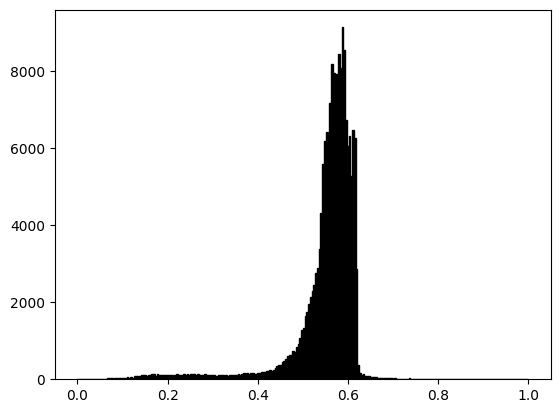

In [41]:
plt.hist(lum_img.ravel(), bins=256, range=(0.0, 1.0), fc='k', ec='k')

Most often, the "interesting" part of the image is around the peak, and you can get extra contrast by clipping the regions above and/or below the peak. In our histogram, it looks like there's not much useful information in the high end (not many white things in the image). Let's adjust the upper limit, so that we effectively "zoom in on" part of the histogram. We do this by passing the clim argument to imshow. You could also do this by calling the set_clim() method of the image plot object, but make sure that you do so in the same cell as your plot command when working with the Jupyter Notebook - it will not change plots from earlier cells.

You can specify the clim in the call to plot.

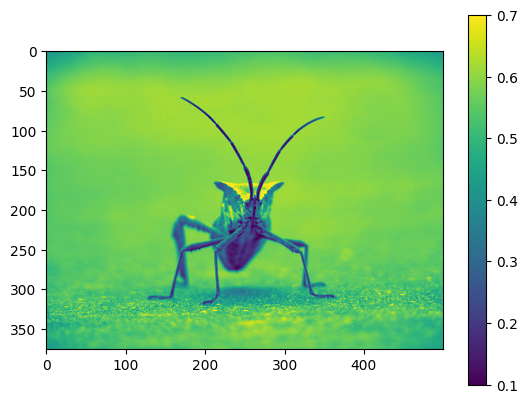

In [42]:
imgplot = plt.imshow(lum_img, clim=(0.1, 0.7))
plt.colorbar()

You can also specify the clim using the returned object

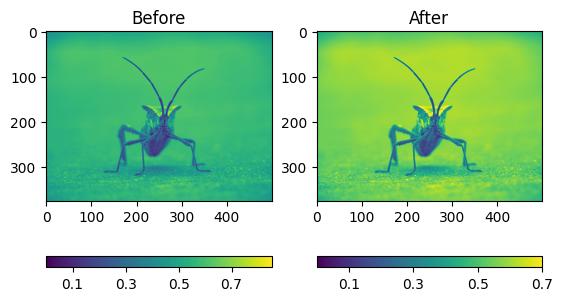

In [44]:
fig = plt.figure()
ax = fig.add_subplot(1, 2, 1)
imgplot = plt.imshow(lum_img)
ax.set_title('Before')
plt.colorbar(ticks=[0.1, 0.3, 0.5, 0.7], orientation='horizontal')

ax = fig.add_subplot(1, 2, 2)
imgplot = plt.imshow(lum_img)
imgplot.set_clim(0.0, 0.7)
ax.set_title('After')
plt.colorbar(ticks=[0.1, 0.3, 0.5, 0.7], orientation='horizontal')

## Tasks

#### Task 1:
Complete the code below to create a image which looks exactly the same as the follow one:

<div align="center">
    <img src="img/task1.png" width="40%">
</div>

Note: you need to set up marker (type, color) and line (type, color, width) style

#### Task 2:

Complete the code below to create a image which looks exactly the same as the follow one:
<div align="center">
    <img src="img/task2.png" width="40%">
</div>
Note: you need to use plt.barh() 
 

#### Task 3:

Complete the code below to create a image which looks exactly the same as the follow one:
<div align="center">
    <img src="img/task3.png" width="40%">
</div>

#### Task 4:

Complete the code below to create a image which looks exactly the same as the follow one:
<div align="center">
    <img src="img/task4.png" width="40%">
</div>

#### Task 5:

Complete the code below to create a image which looks exactly the same as the follow one:
<div align="center">
    <img src="img/task5.png" width="40%">
</div>

Note: the functions that you may need is plt.stackplot().